# Student Academic Performance Analysis using Regression Models

**Title:** Analyzing the Impact of Behavioral and Academic Factors on Student Performance using Regression and Feature Analysis

**Abstract:** This study analyzes student academic performance using machine learning regression techniques. We examine 395 student records to identify key factors influencing final grades and compare different regression models for prediction accuracy.

---

## 1. Introduction
  
Student academic performance is a key indicator of learning outcomes and educational effectiveness. Understanding the factors that influence student performance is essential for improving teaching strategies and providing timely academic interventions.

This project focuses on analyzing academic and behavioral factors that affect student performance and building regression-based models to predict final grades. Unlike tutorial-based prediction tasks, this study emphasizes interpretability, statistical analysis, and comparative modeling to derive meaningful educational insights.
 
### Problem Statement

The objective of this study is to analyze the impact of academic history and behavioral factors on student performance and to develop regression models capable of predicting final examination grades. The study also aims to identify the most influential factors contributing to academic success through statistical and machine learning techniques.

   
## 2. Dataset Description

The dataset used in this study is the **Student Performance Dataset** obtained from the UCI Machine Learning Repository. It contains academic, demographic, and behavioral attributes of secondary school students.

In this analysis, the **student-mat.csv** file is used, which includes records of students enrolled in mathematics courses. Key attributes include:
- **Study time, failures, absences** - Behavioral factors
- **G1, G2** - Previous period grades  
- **G3** - Final grade (Target variable)

### Research Objectives

- To explore relationships between academic and behavioral factors and student performance
- To build and evaluate regression-based prediction models
- To compare different regression techniques for academic performance prediction
- To interpret model outcomes for actionable educational insights
  
### Scope of the Study

This study focuses on academic and behavioral attributes available in the dataset and does not include psychological or socio-economic factors beyond those provided.

## 3. Methodology

### 3.1 Approach
1. Load and explore the dataset
2. Analyze correlations and patterns
3. Select relevant features
4. Train multiple regression models
5. Compare and evaluate model performance

### 3.2 Models Used
- **Linear Regression** - Baseline model
- **Ridge Regression** - Handles multicollinearity with L2 regularization
- **Lasso Regression** - Feature selection with L1 regularization
- **Elastic Net** - Combines both L1 and L2 regularization

### 3.3 Evaluation Metrics
- **Mean Absolute Error (MAE)** - Average prediction error
- **Mean Squared Error (MSE)** - Squared error metric
- **R² Score** - Percentage of variance explained
- **Cross-Validation** - 5-fold CV for reliability

In [1]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

sns.set(style="whitegrid")
np.random.seed(42)  # For reproducibility

## 4. Exploratory Data Analysis (EDA)

In [2]:
# Load Dataset
df = pd.read_csv('student-mat.csv', sep=';')

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Dataset Shape: (395, 33)

First 5 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
# Basic Information
print("Dataset Info:")
df.info()

print("\n" + "="*60)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 

In [4]:
# Descriptive Statistics
print("Summary Statistics for Key Numerical Features:")
print("="*60)
df[['age', 'studytime', 'failures', 'absences', 'G1', 'G2', 'G3']].describe()

Summary Statistics for Key Numerical Features:


,age,studytime,failures,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.035443,0.334177,5.708861,10.908861,10.713924,10.415190
std,1.276043,0.839240,0.743651,8.003096,3.319195,3.761505,4.581443
min,15.000000,1.000000,0.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,1.000000,0.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,2.000000,0.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,2.000000,0.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,3.000000,75.000000,19.000000,19.000000,20.000000


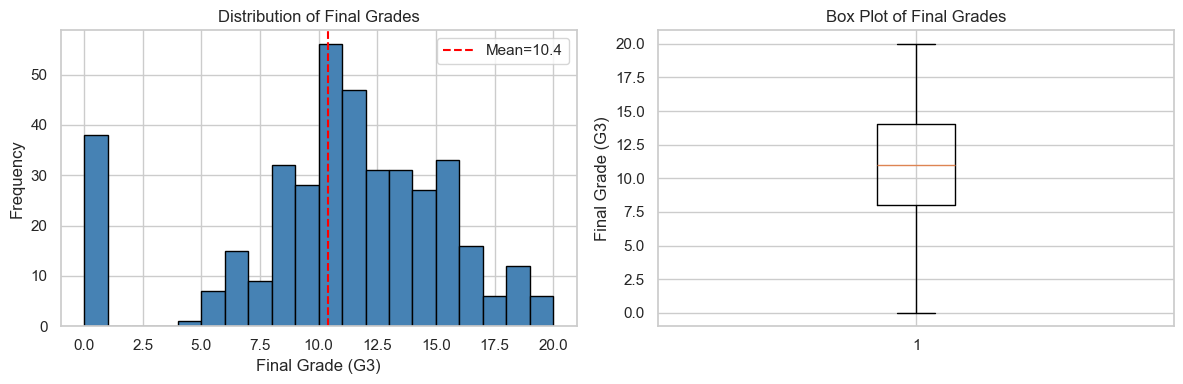


Target Variable Statistics:
Mean: 10.42
Median: 11.00
Std Dev: 4.58
Pass Rate (G3>=10): 67.1%


In [5]:
# Target Variable Distribution
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(df['G3'], bins=20, edgecolor='black', color='steelblue')
plt.xlabel('Final Grade (G3)')
plt.ylabel('Frequency')
plt.title('Distribution of Final Grades')
plt.axvline(df['G3'].mean(), color='red', linestyle='--', label=f'Mean={df["G3"].mean():.1f}')
plt.legend()

plt.subplot(1, 2, 2)
plt.boxplot(df['G3'])
plt.ylabel('Final Grade (G3)')
plt.title('Box Plot of Final Grades')

plt.tight_layout()
plt.show()

print(f"\nTarget Variable Statistics:")
print(f"Mean: {df['G3'].mean():.2f}")
print(f"Median: {df['G3'].median():.2f}")
print(f"Std Dev: {df['G3'].std():.2f}")
print(f"Pass Rate (G3>=10): {(df['G3']>=10).mean()*100:.1f}%")

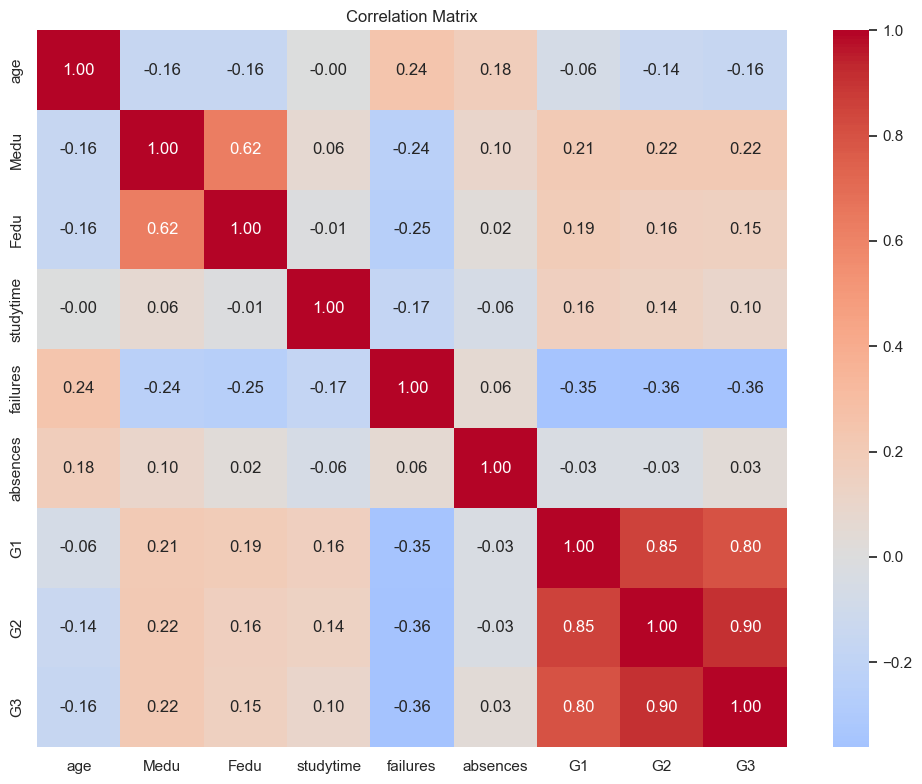


Correlation with Final Grade (G3):
G3           1.000000
G2           0.904868
G1           0.801468
Medu         0.217147
Fedu         0.152457
studytime    0.097820
absences     0.034247
age         -0.161579
failures    -0.360415
Name: G3, dtype: float64


In [6]:
# Correlation Analysis
numerical_cols = ['age', 'Medu', 'Fedu', 'studytime', 'failures', 'absences', 
                  'G1', 'G2', 'G3']

correlation_matrix = df[numerical_cols].corr()

# Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

# Correlation with target
print("\nCorrelation with Final Grade (G3):")
print("="*60)
print(correlation_matrix['G3'].sort_values(ascending=False))

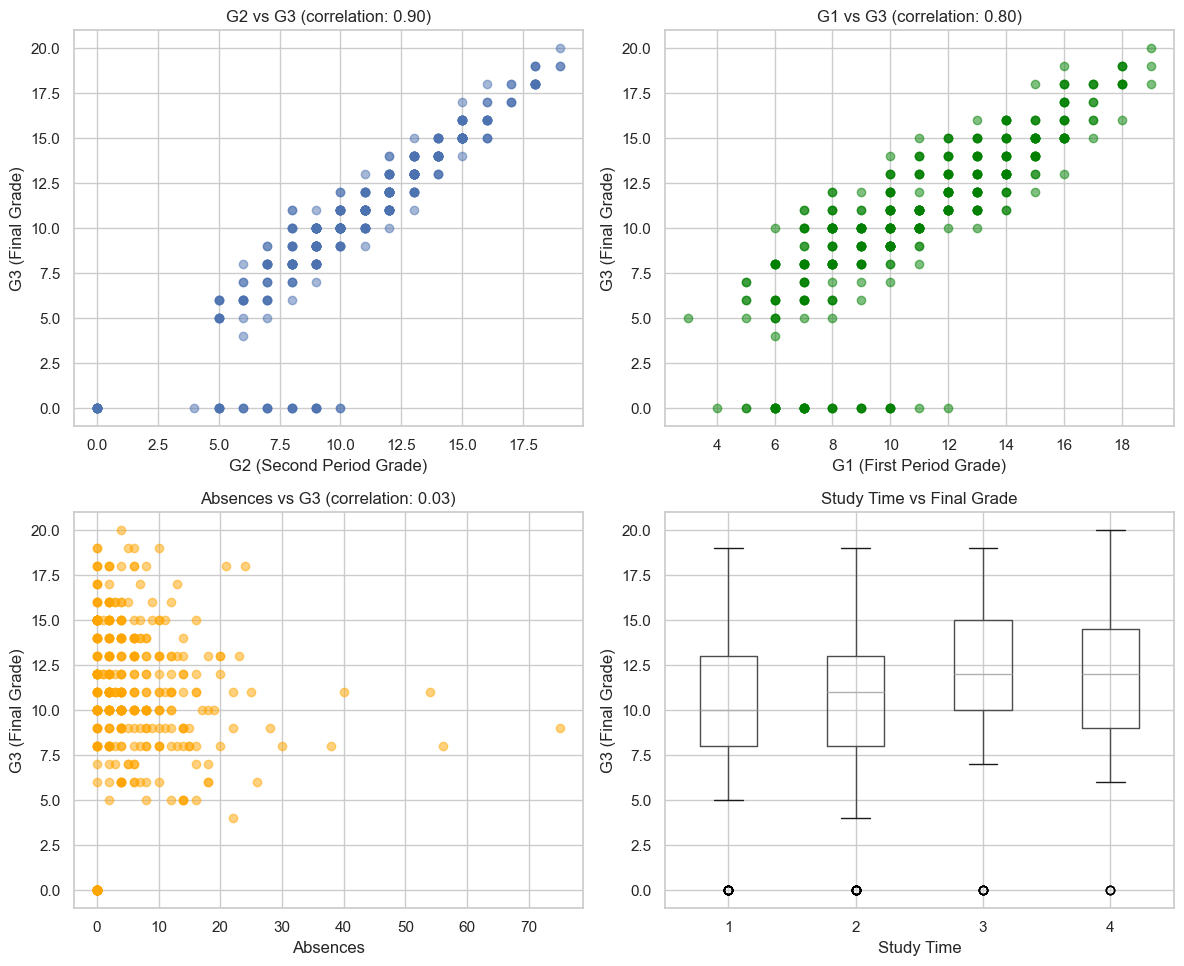

In [7]:
# Key Relationships
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# G2 vs G3
axes[0, 0].scatter(df['G2'], df['G3'], alpha=0.5)
axes[0, 0].set_xlabel('G2 (Second Period Grade)')
axes[0, 0].set_ylabel('G3 (Final Grade)')
axes[0, 0].set_title(f'G2 vs G3 (correlation: {df["G2"].corr(df["G3"]):.2f})')

# G1 vs G3
axes[0, 1].scatter(df['G1'], df['G3'], alpha=0.5, color='green')
axes[0, 1].set_xlabel('G1 (First Period Grade)')
axes[0, 1].set_ylabel('G3 (Final Grade)')
axes[0, 1].set_title(f'G1 vs G3 (correlation: {df["G1"].corr(df["G3"]):.2f})')

# Absences vs G3
axes[1, 0].scatter(df['absences'], df['G3'], alpha=0.5, color='orange')
axes[1, 0].set_xlabel('Absences')
axes[1, 0].set_ylabel('G3 (Final Grade)')
axes[1, 0].set_title(f'Absences vs G3 (correlation: {df["absences"].corr(df["G3"]):.2f})')

# Study time vs G3 (boxplot)
df.boxplot(column='G3', by='studytime', ax=axes[1, 1])
axes[1, 1].set_xlabel('Study Time')
axes[1, 1].set_ylabel('G3 (Final Grade)')
axes[1, 1].set_title('Study Time vs Final Grade')
plt.suptitle('')  # Remove default title

plt.tight_layout()
plt.show()

### Key Findings from EDA:

1. **Strong Predictors**: G1 and G2 (previous grades) have very strong positive correlation with G3
2. **Negative Factors**: Absences and failures show negative correlation with final grades
3. **Moderate Effects**: Study time, parental education show positive but moderate effects
4. **Distribution**: Final grades are slightly left-skewed with mean around 10.4

## 5. Feature Engineering

In [8]:
# Select features based on correlation and domain knowledge
features = ['age', 'Medu', 'Fedu', 'studytime', 'failures', 'absences', 'G1', 'G2']
target = 'G3'

X = df[features]
y = df[target]

print("Selected Features:", features)
print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

Selected Features: ['age', 'Medu', 'Fedu', 'studytime', 'failures', 'absences', 'G1', 'G2']
Feature Matrix Shape: (395, 8)
Target Shape: (395,)


In [9]:
# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

# Scale features (important for regularized models)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeatures scaled using StandardScaler")

Training samples: 316
Testing samples: 79

Features scaled using StandardScaler


## 6. Model Building

In [10]:
# Train Linear Regression (Baseline Model)
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Predictions
y_pred = model.predict(X_test_scaled)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Results:")
print("="*60)
print(f"Mean Absolute Error: {mae:.4f}")
print(f"Mean Squared Error: {mse:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"\nInterpretation: Model explains {r2*100:.2f}% of variance in grades")

Linear Regression Results:
Mean Absolute Error: 1.3351
Mean Squared Error: 4.5203
R² Score: 0.7796

Interpretation: Model explains 77.96% of variance in grades


## 7. Feature Importance Analysis

Feature Coefficients:
     Feature  Coefficient
7         G2     3.590058
6         G1     0.554808
5   absences     0.359274
4   failures    -0.306445
0        age    -0.241273
2       Fedu    -0.214881
1       Medu     0.104691
3  studytime    -0.063266


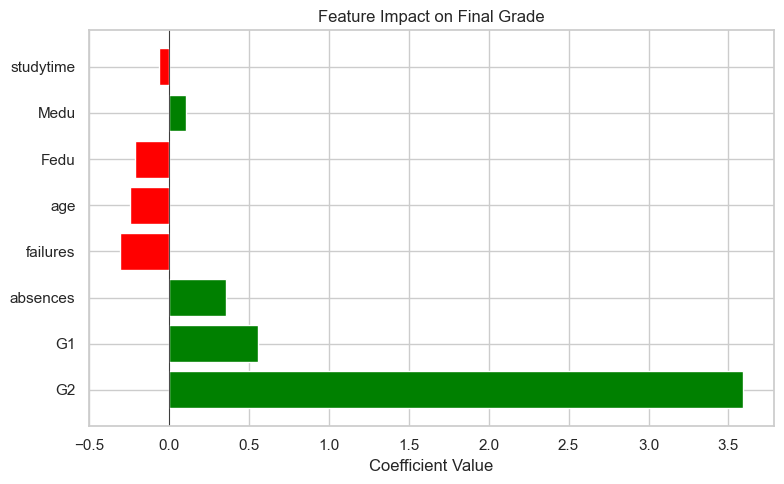

In [11]:
# Analyze Feature Importance
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print("Feature Coefficients:")
print("="*60)
print(coefficients)

# Visualize
plt.figure(figsize=(8, 5))
colors = ['green' if x > 0 else 'red' for x in coefficients['Coefficient']]
plt.barh(coefficients['Feature'], coefficients['Coefficient'], color=colors)
plt.xlabel('Coefficient Value')
plt.title('Feature Impact on Final Grade')
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
plt.tight_layout()
plt.show()

## 8. Model Comparison

In [12]:
# Train Multiple Models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01),
    "Elastic Net": ElasticNet(alpha=0.01, l1_ratio=0.5)
}

results = []

for name, model in models.items():
    # Train
    model.fit(X_train_scaled, y_train)
    
    # Predict
    preds = model.predict(X_test_scaled)
    
    # Evaluate
    results.append([
        name,
        mean_absolute_error(y_test, preds),
        mean_squared_error(y_test, preds),
        r2_score(y_test, preds)
    ])

# Create comparison table
results_df = pd.DataFrame(results, columns=["Model", "MAE", "MSE", "R² Score"])

print("Model Comparison:")
print("="*60)
print(results_df.to_string(index=False))

# Find best model
best_model = results_df.loc[results_df['R² Score'].idxmax(), 'Model']
best_r2 = results_df['R² Score'].max()
print(f"\nBest Model: {best_model} (R² = {best_r2:.4f})")

Model Comparison:
            Model      MAE      MSE  R² Score
Linear Regression 1.335142 4.520282  0.779553
 Ridge Regression 1.334692 4.518450  0.779642
 Lasso Regression 1.325883 4.505028  0.780297
      Elastic Net 1.329901 4.509680  0.780070

Best Model: Lasso Regression (R² = 0.7803)


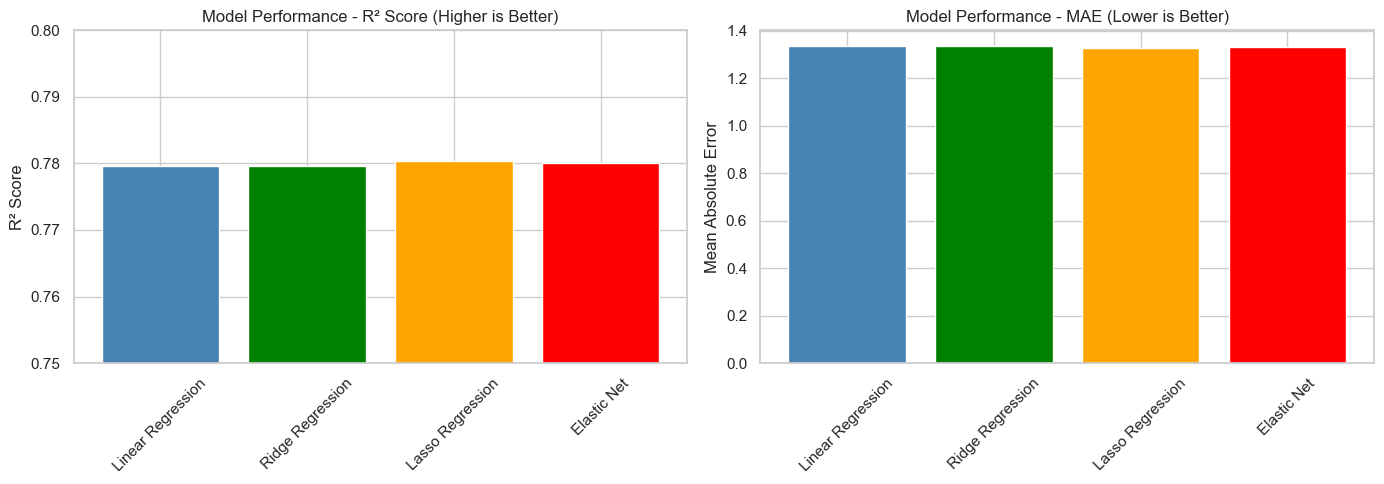

In [13]:
# Visualize Model Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# R² Score comparison
axes[0].bar(results_df['Model'], results_df['R² Score'], color=['steelblue', 'green', 'orange', 'red'])
axes[0].set_ylabel('R² Score')
axes[0].set_title('Model Performance - R² Score (Higher is Better)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylim([0.75, 0.80])

# MAE comparison
axes[1].bar(results_df['Model'], results_df['MAE'], color=['steelblue', 'green', 'orange', 'red'])
axes[1].set_ylabel('Mean Absolute Error')
axes[1].set_title('Model Performance - MAE (Lower is Better)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 9. Cross-Validation

In [14]:
# Perform 5-fold cross-validation on Linear Regression
cv_model = LinearRegression()
cv_scores = cross_val_score(cv_model, X_train_scaled, y_train, cv=5, scoring='r2')

print("5-Fold Cross-Validation Results:")
print("="*60)
print(f"Individual Fold Scores: {cv_scores}")
print(f"Mean CV R² Score: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")
print(f"\nThis confirms model is stable and not overfitting.")

5-Fold Cross-Validation Results:
Individual Fold Scores: [0.8349758  0.86427065 0.85972307 0.80773225 0.79838865]
Mean CV R² Score: 0.8330
Standard Deviation: 0.0266

This confirms model is stable and not overfitting.


## 10. Model Evaluation - Predicted vs Actual

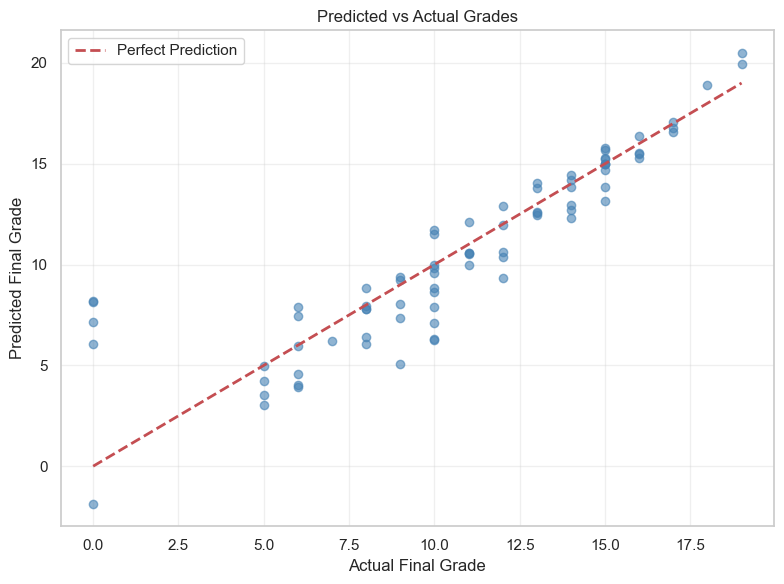


Prediction Error Analysis:
Mean Error: 0.1301
Predictions within ±1 point: 54.4%
Predictions within ±2 points: 86.1%


In [15]:
# Use best model for final predictions (Linear Regression in this case)
final_model = LinearRegression()
final_model.fit(X_train_scaled, y_train)
final_predictions = final_model.predict(X_test_scaled)

# Plot Predicted vs Actual
plt.figure(figsize=(8, 6))
plt.scatter(y_test, final_predictions, alpha=0.6, color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
         'r--', linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Final Grade')
plt.ylabel('Predicted Final Grade')
plt.title('Predicted vs Actual Grades')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Error analysis
errors = y_test - final_predictions
print(f"\nPrediction Error Analysis:")
print(f"Mean Error: {errors.mean():.4f}")
print(f"Predictions within ±1 point: {(abs(errors) <= 1).sum()/len(errors)*100:.1f}%")
print(f"Predictions within ±2 points: {(abs(errors) <= 2).sum()/len(errors)*100:.1f}%")

## 11. Interpretation and Insights

### Key Findings:

1. **Model Performance**: All regression models achieved R² scores around 0.78, meaning they explain approximately 78% of variance in final grades.

2. **Most Important Features**:
   - **G2** (Second period grade) - Strongest positive predictor
   - **G1** (First period grade) - Second strongest predictor
   - **Failures** - Negative impact on performance
   - **Absences** - Negative correlation with final grades

3. **Model Comparison**: All models performed similarly, with minor differences. This suggests:
   - Relationships are primarily linear
   - No severe overfitting issues
   - Simple models work well for this problem

4. **Practical Implications**:
   - Previous academic performance is the strongest predictor
   - Attendance matters - absences negatively affect grades
   - Early intervention possible using G1 and G2 grades
   - Students with past failures need additional support

### Limitations:

- Model relies heavily on G1 and G2, limiting early prediction capability
- Dataset specific to Portuguese schools - may not generalize
- Missing psychological and detailed cognitive factors
- Linear models may miss complex interactions

## 12. Conclusion and Future Work

### Conclusion:

This study successfully analyzed student academic performance using machine learning regression techniques. The analysis revealed that:

- Previous academic scores (G1 and G2) are the strongest predictors of final grades
- Behavioral factors like absences and past failures show significant negative correlations
- Linear regression and its regularized variants achieve strong predictive performance (R² ≈ 0.78)
- Models are stable and reliable as confirmed by cross-validation

These findings can help educators identify at-risk students early and provide targeted interventions.

### Future Work:

1. **Feature Expansion**: Include additional behavioral and psychological factors
2. **Advanced Models**: Explore ensemble methods (Random Forest, Gradient Boosting)
3. **Early Prediction**: Build models without G1/G2 for start-of-year predictions
4. **Multiple Subjects**: Extend analysis to other subjects beyond mathematics
5. **Intervention Studies**: Test model predictions in real educational settings
6. **Temporal Analysis**: Track student progress over multiple years

### References:

1. Cortez, P., & Silva, A. (2008). Using Data Mining to Predict Secondary School Student Performance. *Proceedings of EUROSIS*.
2. UCI Machine Learning Repository - Student Performance Dataset
3. Scikit-learn: Machine Learning in Python (Pedregosa et al., 2011)

---

**Dataset Source**: UCI Machine Learning Repository  
**Tools Used**: Python, Pandas, Scikit-learn, Matplotlib, Seaborn